# Step 3 – Exploratory Data Analysis

Plan reference: `schneider_problem1_plan.md`, Step 3. This notebook builds on the team's Step 1 and Step 2 code:

| Module | Role |
|---|---|
| `src/data_prep.py` (Step 1, Karin) | cleaned monthly panel, publication lags, targets |
| `src/cost_model.py` (Step 2, Karin) | masses, €/t levels, drivers, product cases, BOM index |
| `src/data_loading.py` | reads the Step 1 panel and renames 25 series to short EDA names |
| `src/eda_cost.py` | reshapes the Step 2 output for the EDA (€ per material, market-price variant, unit cost) |
| `src/eda.py`, `src/plotting.py` | statistics and charts |

Run first, from the repo root: `uv run python -m src.data_prep` then `uv run python -m src.cost_model`.
Assumptions: `configs/eda.yaml`. Charts: `plots/step3/`. Tables: `report/problem1/step3_tables/`.
Report: `report/problem1/step3_eda.md`.

In [1]:
import os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
# Step 1 and Step 2 code use paths relative to the repo root.
if Path.cwd().name == "analysis":
    os.chdir("..")

import numpy as np
import pandas as pd
from IPython.display import display

from src.config import load_config
from src import data_loading as dl, eda, eda_cost as ec, plotting as pl
from src import cost_model as cm

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pl.set_style()

cfg = load_config("eda")
P = cfg["paths"]
PLOTS, TABLES = P["plots"], P["tables"]
TABLES.mkdir(parents=True, exist_ok=True)
H, REG, B = cfg["horizons"], cfg["regimes"], cfg["business"]

def save(df, name):
    df.to_csv(TABLES / f"{name}.csv")
    return df

## 0. Data and quality checks

The panel is the Step 1 output (`Data/processed/panel_monthly.csv`), cut at the September 2026 origin.
For the EDA we keep 25 series and give them short names.

In [2]:
panel = dl.build_eur_panel(P)
display(save(dl.coverage_table(panel), "coverage"))

,step1_id,label,first,last,n_obs,internal_gaps
series,,,,,,
cu_eur,LME_CU_CASH_EUR,Copper LME (EUR/t),2016-01,2026-09,129,0
al_eur,LME_AL_CASH_EUR,Aluminium LME (EUR/t),2016-01,2026-09,129,0
ni_eur,S03_EUR,Nickel LME (EUR/t),2016-11,2026-09,119,0
zn_eur,S05_EUR,Zinc LME (EUR/t),2016-11,2026-09,119,0
iron_ore_eur,S04_EUR,Iron ore 62% (EUR/t),2016-11,2026-09,119,0
eurusd,S06,EUR/USD (USD per EUR),2016-11,2026-09,119,0
steel_cr_de,MEPS_DE_CR,CR coil Germany MEPS (EUR/t),2012-11,2026-09,167,0
steel_cr_fr,MEPS_FR_CR,CR coil France MEPS (EUR/t),2012-11,2026-09,167,0
steel_hdg_de,MEPS_DE_HDG,HDG coil Germany MEPS (EUR/t),2012-11,2026-09,167,0


In [3]:
# Westmetall LME cash (EUR) vs IMF-based D01 / D02
display(dl.lme_vs_imf_check(P))

,n_months,median_abs_diff_pct,max_abs_diff_pct
copper,119.0,0.123,0.788
aluminium,119.0,0.182,1.128


In [4]:
# Data-quality scan: isolated one-month spikes (typo-like).
raw_ep = dl.load_epoxy_raw(P)
print("Raw epoxy file:", {c: list(raw_ep.index[dl.isolated_spikes(raw_ep[c])].strftime("%Y-%m")) for c in raw_ep})
print("Step 1 panel  :", {c: list(panel.index[dl.isolated_spikes(panel[c])].strftime("%Y-%m"))
                          for c in panel if dl.isolated_spikes(panel[c]).any()})
display(pd.concat({"raw file": raw_ep[["epichlorohydrin", "epoxy"]],
                   "Step 1 panel": dl.load_step1_panel(P)[["ECH_EUR", "EPOXY_EUR"]].set_axis(["epichlorohydrin", "epoxy"], axis=1)},
                  axis=1).loc["2026-03":"2026-07"].round(0))

Raw epoxy file: {'benzene': [], 'acetone': [], 'epichlorohydrin': ['2026-05'], 'epoxy_other_costs': [], 'epoxy': []}
Step 1 panel  : {'power_fr': ['2025-05']}


raw file            Step 1 panel        
           epichlorohydrin   epoxy epichlorohydrin   epoxy
month                                                     
2026-03-01          2154.0  4556.0          2154.0  4556.0
2026-04-01          2479.0  4928.0          2479.0  4928.0
2026-05-01           257.0  3593.0          2543.0  4956.0
2026-06-01          2607.0  4983.0          2607.0  4983.0
2026-07-01          2503.0  4877.0          2503.0  4877.0

In [5]:
# Teardown should-cost (EUR). SGC: total €19 is clearly an error in the source.
display(dl.load_teardown_costs(P))
bench = dl.load_rmu_benchmark(P)
display(bench.pivot(index="year", columns="brand", values="p50"))

,total,material,process,labour,overhead,insulation
Schneider,3008.865,2403.985,21.540,30.691,552.649,SF6
ormazabal,1692.365,1450.649,7.508,13.465,220.743,SF6
SGC – SwitchGear Company nv,19.352,11.537,2.155,3.135,2.524,SF6
ABB,3462.286,2842.083,6.469,12.842,600.893,SF6
Siemens,3307.334,2679.004,7.240,13.620,607.469,SF6
eaton,767.360,641.368,14.864,11.037,100.090,Air/vacuum


brand,ABB,Eaton,Ormazabal,Schneider Electric,Siemens,SwitchGear Company
year,,,,,,
2017,7181.0,9948.0,5709.0,7230.0,8450.0,5490.0
2018,7208.0,10092.0,5687.0,7295.0,8450.0,5513.0
2019,7308.0,9670.0,5758.0,7318.0,8484.0,5489.0
2020,7227.0,9810.0,5683.0,7261.0,8486.0,5475.0
2021,7744.0,10440.0,6316.0,7748.0,9203.0,5846.0
2022,8205.0,10634.0,6643.0,8311.0,9852.0,6216.0
2023,8747.0,10772.0,6944.0,8407.0,10302.0,6648.0
2024,8794.0,10772.0,7097.0,8727.0,10316.0,6800.0
2025,8782.0,10661.0,7107.0,8740.0,10318.0,6921.0


## 3.1 Univariate analysis

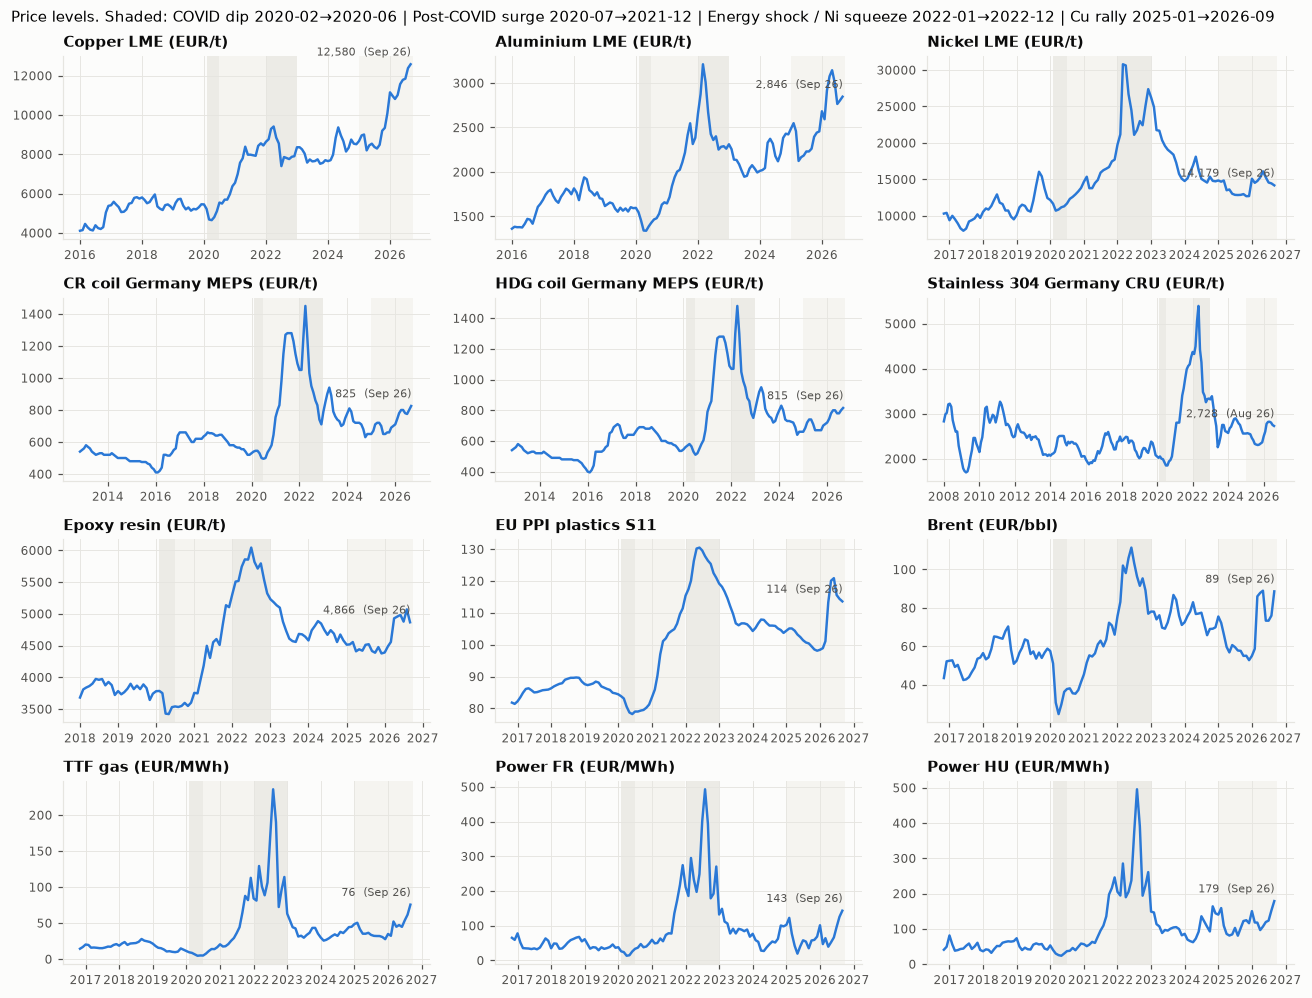

In [6]:
KEY = ["cu_eur", "al_eur", "ni_eur", "steel_cr_de", "steel_hdg_de", "ss304_de",
       "epoxy", "ppi_plastics", "brent_eur", "ttf_eur", "power_fr", "power_hu"]
pl.price_history(panel, KEY, REG, PLOTS);

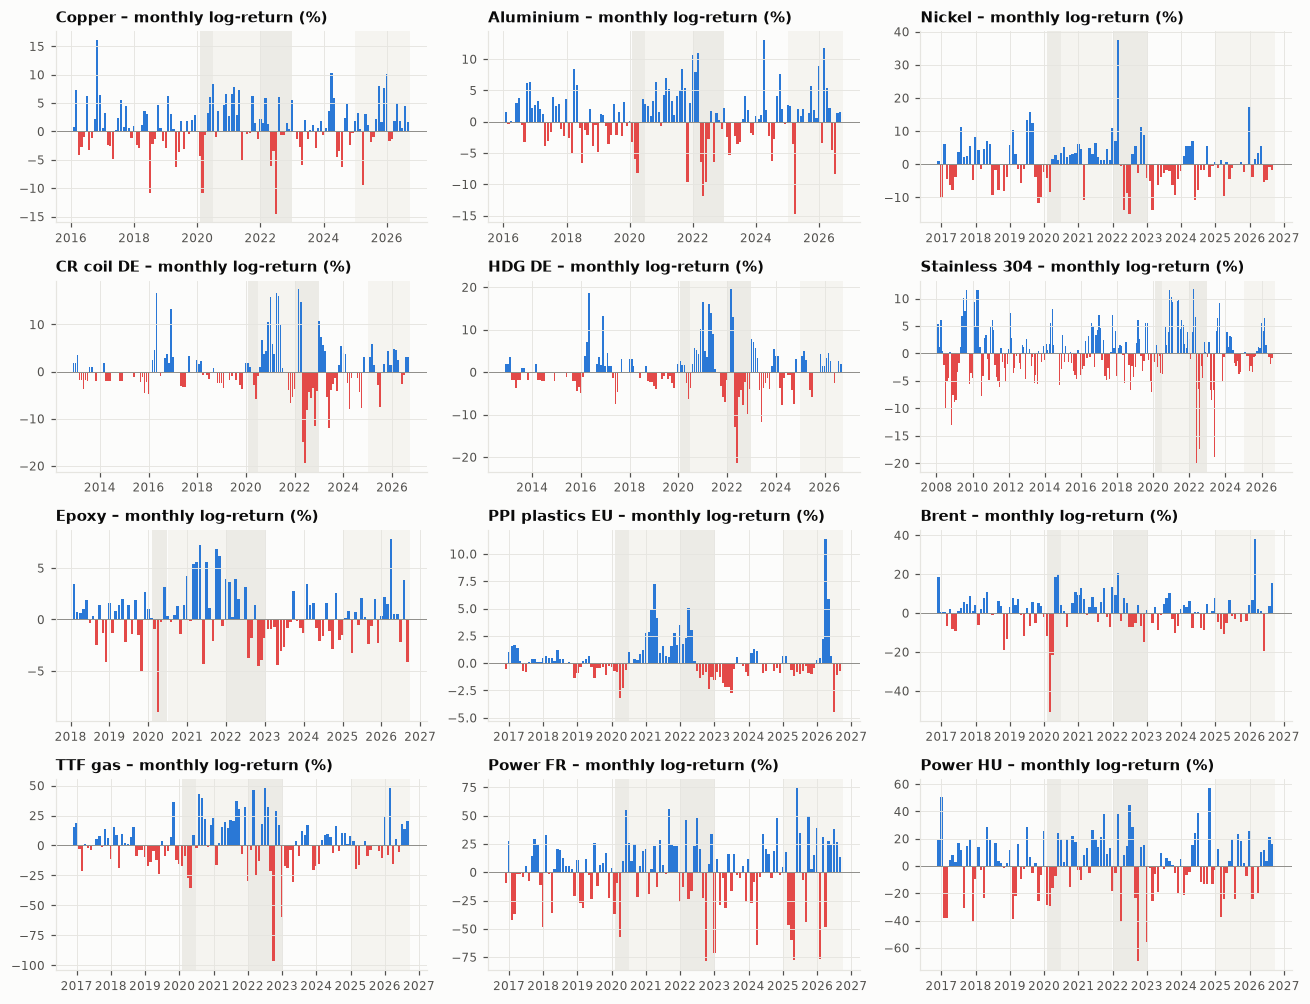

In [7]:
rets = eda.log_returns(panel)
pl.returns_grid(rets, KEY, REG, PLOTS);

In [8]:
ALL = [c for c in panel.columns if c != "eurusd"] + ["eurusd"]
summ = save(eda.return_summary(rets[ALL]), "return_summary")
display(summ.sort_values("vol_%/yr", ascending=False))

,n,mean_%/m,vol_%/m,vol_%/yr,skew,excess_kurt,JB_p,worst_m_%,best_m_%
Power FR,118.0,0.667,29.942,103.721,-0.545,0.268,4.524e-02,-78.803,74.380
Power DE,118.0,1.133,22.352,77.430,-0.566,1.782,1.735e-05,-81.457,67.037
Power HU,118.0,1.255,21.768,75.407,-0.381,0.481,1.360e-01,-69.983,57.121
TTF gas,118.0,1.408,20.467,70.900,-0.755,3.921,1.416e-19,-96.739,47.957
Benzene,104.0,0.168,19.809,68.622,-2.597,14.192,1.248e-215,-125.561,31.171
Brent,118.0,0.604,9.771,33.849,-0.811,6.973,1.923e-55,-50.943,38.190
Iron ore,118.0,0.203,9.032,31.289,-0.915,2.162,2.731e-09,-35.426,21.303
Nickel,118.0,0.270,7.156,24.790,1.148,5.054,1.257e-33,-14.883,37.432
HR coil DE,166.0,0.275,6.239,21.613,0.486,3.774,1.518e-23,-24.512,27.663
Zinc,118.0,0.326,5.699,19.743,-0.266,0.321,3.869e-01,-15.153,15.008


### H-month changes — first naive cost-at-risk
Overlapping windows: with ~120 months, H = 9 gives ~110 overlapping but only ~13 independent windows.

n_overlapping  n_independent   q05_%  q50_%   q95_%  P(rise>10%)
series          H                                                                  
Copper          3            126             42  -9.427  2.154  18.960        0.175
                6            123             20 -10.304  3.346  30.271        0.341
                9            120             13 -10.141  4.896  40.177        0.367
Aluminium       3            126             42 -11.056  1.628  17.703        0.175
                6            123             20 -13.690  2.564  28.702        0.333
                9            120             13 -14.784  1.876  38.069        0.375
CR coil DE      3            164             54 -14.812 -1.042  26.819        0.171
                6            161             26 -17.969 -2.703  52.525        0.211
                9            158             17 -19.921 -3.093  53.961        0.215
HDG DE          3            164             54 -14.613 -0.997  27.681        0.171
                6            161             26 -16.842 -2.041  48.837        0.205
                9            158             17 -19.320 -2.830  57.198        0.234
Stainless 304   3            221             73 -17.597 -0.973  21.783        0.181
                6            218             36 -25.080 -1.980  38.109        0.261
                9            215             23 -28.522 -3.902  43.549        0.284
Epoxy           3            102             34  -6.808  0.359  10.404        0.059
                6             99             16 -11.314  0.052  19.611        0.222
                9             96             10 -14.704 -1.202  28.268        0.240
PPI plastics EU 3            116             38  -5.209  0.047  11.583        0.069
                6            113             18  -8.211 -0.666  21.624        0.177
                9            110             12 -11.124 -0.660  27.631        0.227
Nickel          3            116             38 -18.382  0.362  22.444        0.302
                6            113             18 -25.754  2.751  34.189        0.372
                9            110             12 -27.799  2.315  47.568        0.427
PPI steel EU    3            116             38  -5.933 -0.404  15.381        0.103
                6            113             18 -10.516 -0.874  27.458        0.168
                9            110             12 -13.693 -1.844  40.212        0.200

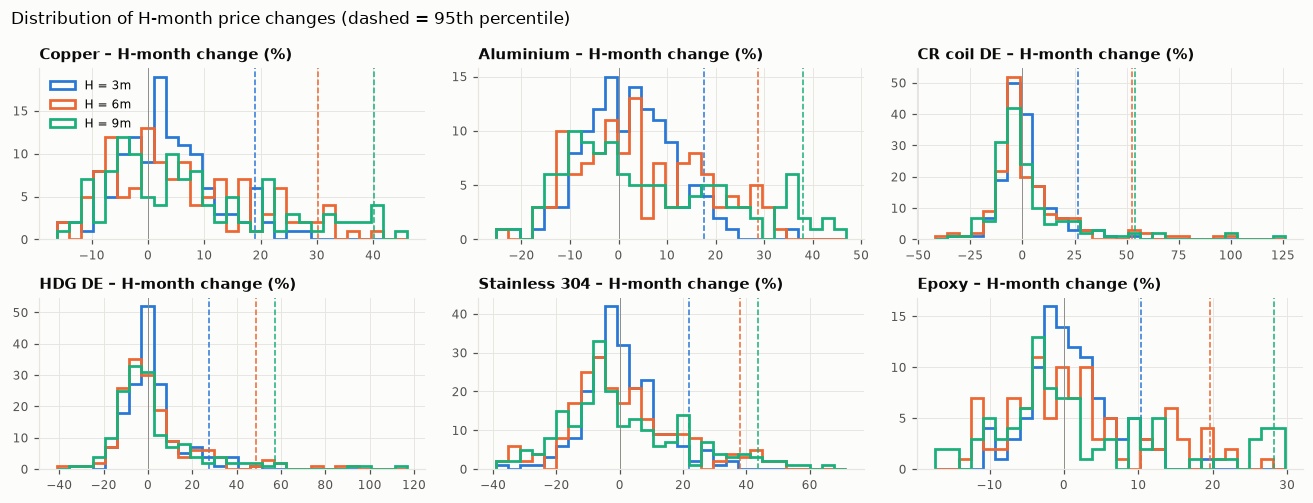

In [9]:
MAT = ["cu_eur", "al_eur", "steel_cr_de", "steel_hdg_de", "ss304_de", "epoxy"]
q = save(eda.h_change_quantiles(panel, MAT + ["ppi_plastics", "ni_eur", "ppi_steel"], H), "h_change_quantiles")
display(q)
pl.h_change_hist(panel, MAT, H, PLOTS);

### PPI vs market price
Is the Eurostat PPI calmer than the market price, and does it lag it? This matters for Step 2, which moves
carbon steel and stainless with the S09 PPI.

,,n,vol_market_%/yr,vol_ppi_%/yr,ratio_ppi/market,corr_lag0,best_lead_m,corr_best,corr_levels
market,ppi,,,,,,,,
Copper,PPI Cu,118,14.595,9.636,0.660,0.933,0,0.933,0.992
Aluminium,PPI Al,118,16.270,5.636,0.346,0.424,1,0.634,0.912
CR coil DE,PPI steel DE,118,19.808,7.243,0.366,0.553,1,0.576,0.741
Stainless 304,PPI steel EU,117,17.978,7.468,0.415,0.539,0,0.539,0.826
HDG DE,PPI steel DE,118,19.516,7.243,0.371,0.573,0,0.573,0.731
CR coil DE,PPI steel EU,118,19.808,7.436,0.375,0.579,1,0.686,0.784


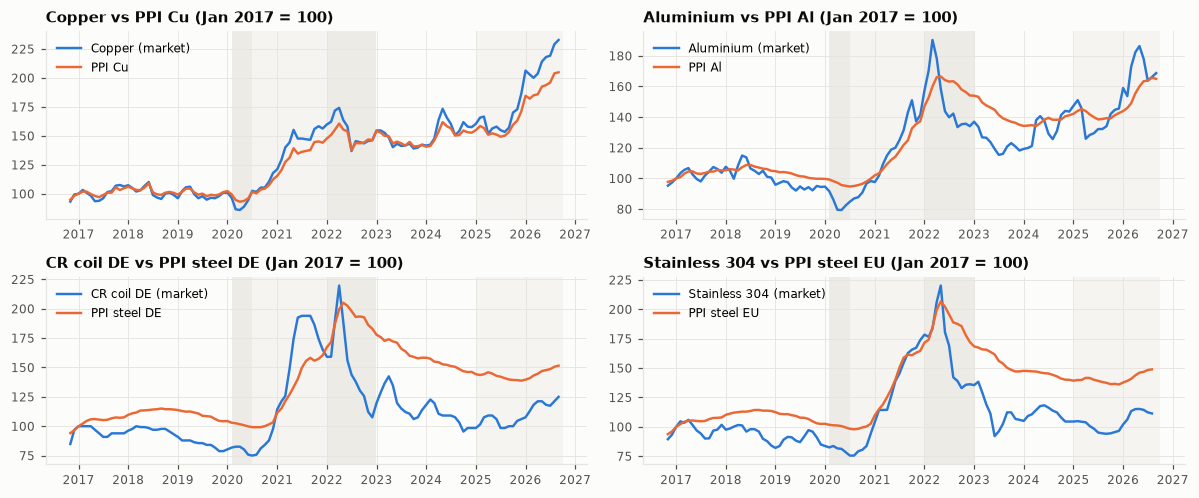

In [10]:
PAIRS = [("cu_eur", "ppi_cu"), ("al_eur", "ppi_al"), ("steel_cr_de", "ppi_steel_de"),
         ("ss304_de", "ppi_steel"), ("steel_hdg_de", "ppi_steel_de"), ("steel_cr_de", "ppi_steel")]
display(save(eda.vol_comparison(panel, PAIRS), "ppi_vs_market"))
pl.ppi_vs_market(panel, PAIRS[:4], REG, PLOTS);

### Volatility clustering

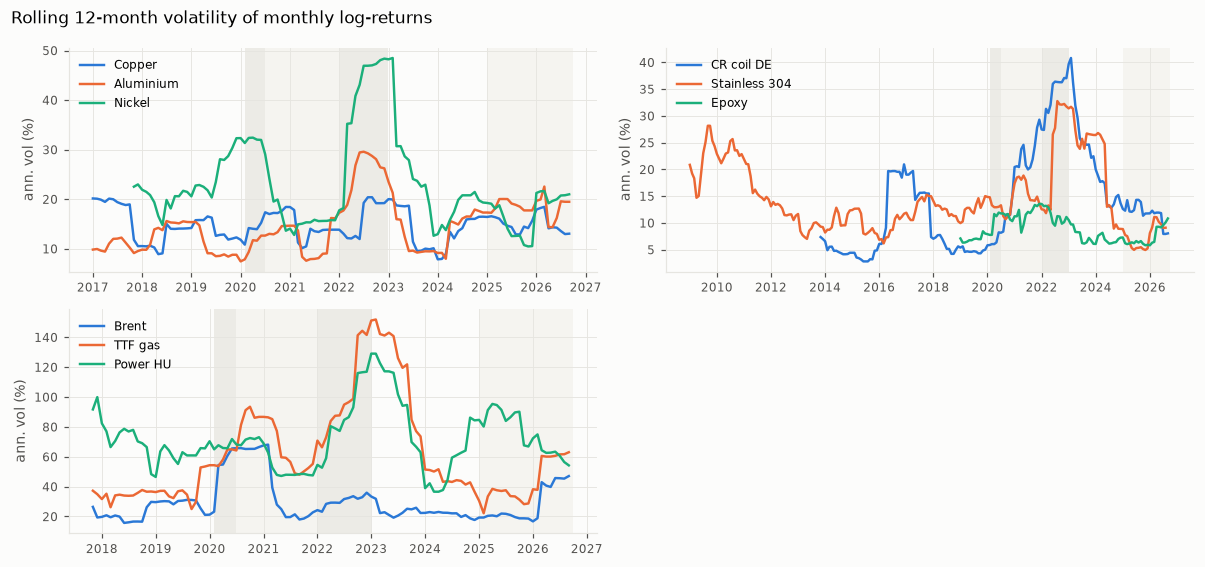

In [11]:
rv = eda.rolling_vol(rets)
pl.rolling_vol_plot(rv, ["cu_eur", "al_eur", "ni_eur", "steel_cr_de", "ss304_de", "epoxy",
                         "brent_eur", "ttf_eur", "power_hu"], REG, PLOTS);

,acf_r2_lag1,acf_r2_lag3,LB_p_r2_lag12,acf_r_lag1
Copper,0.002,-0.054,9.571e-01,0.203
Aluminium,0.129,0.105,1.205e-01,0.300
Nickel,-0.011,-0.011,7.015e-01,0.285
Zinc,0.200,0.122,6.648e-01,0.136
Iron ore,0.308,0.223,1.206e-02,0.223
CR coil DE,0.453,0.254,2.053e-15,0.535
CR coil FR,0.474,0.289,1.579e-16,0.538
HDG DE,0.314,0.324,7.335e-08,0.531
HR coil DE,0.255,0.310,1.187e-08,0.508
Stainless 304,0.163,0.089,1.857e-14,0.469


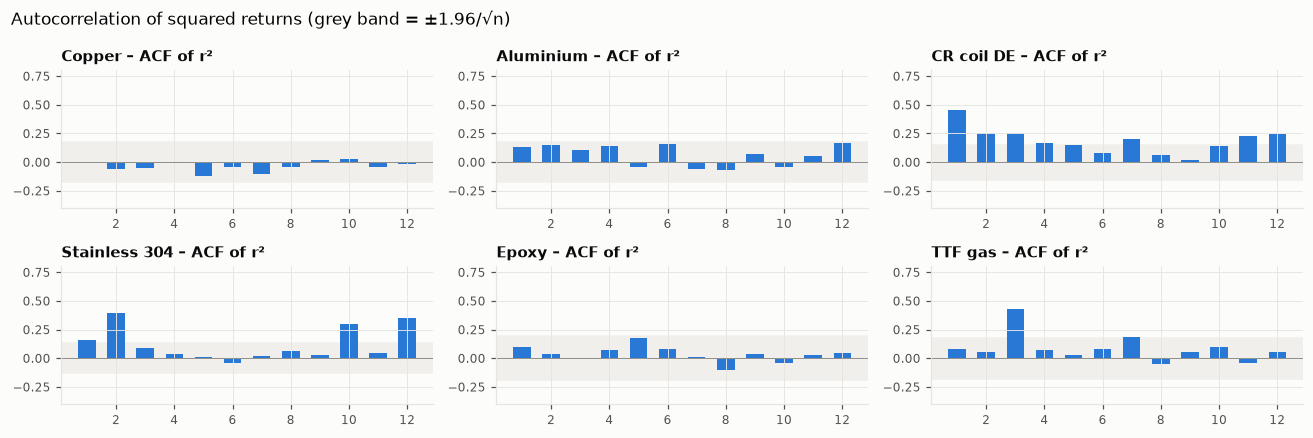

In [12]:
display(save(eda.arch_effects(rets[ALL]), "arch_effects"))
pl.acf_squared(rets, ["cu_eur", "al_eur", "steel_cr_de", "ss304_de", "epoxy", "ttf_eur"], PLOTS);

### Stationarity (ADF: H0 unit root; KPSS: H0 stationary)
Common 2016-11 → 2026-09 window.

In [13]:
win = panel.loc["2016-11":"2026-09"]
display(save(eda.stationarity(win, ALL), "stationarity"))

,ADF_p_level,KPSS_p_level,ADF_p_return,KPSS_p_return,level_verdict,return_verdict
Copper,0.954,0.010,3.185e-02,0.1,non-stationary,stationary
Aluminium,0.583,0.010,1.033e-10,0.1,non-stationary,stationary
Nickel,0.304,0.010,2.371e-12,0.1,non-stationary,stationary
Zinc,0.374,0.100,7.079e-16,0.1,ambiguous,stationary
Iron ore,0.518,0.010,8.946e-11,0.1,non-stationary,stationary
CR coil DE,0.047,0.073,1.260e-01,0.1,stationary,check
CR coil FR,0.067,0.054,1.338e-05,0.1,ambiguous,stationary
HDG DE,0.050,0.090,1.340e-01,0.1,ambiguous,check
HR coil DE,0.358,0.068,3.523e-11,0.1,ambiguous,stationary
Stainless 304,0.267,0.090,3.264e-09,0.1,ambiguous,stationary


### Seasonality (calendar-month effect on returns)

In [14]:
SEAS = ["ppi_cu", "ppi_al", "ppi_steel", "ppi_plastics", "steel_cr_de", "cu_eur",
        "epoxy", "brent_eur", "ttf_eur", "power_fr", "power_hu", "power_de"]
display(save(eda.seasonality_test(rets[SEAS]), "seasonality"))

,F_p,KruskalWallis_p,max_month_mean_%,min_month_mean_%,peak_month,trough_month
PPI Cu,0.487,0.683,2.057,-1.109,1.0,7.0
PPI Al,0.844,0.774,1.149,-0.102,1.0,7.0
PPI steel EU,0.221,0.107,1.696,-0.557,4.0,11.0
PPI plastics EU,0.056,0.224,2.135,-0.896,4.0,7.0
CR coil DE,0.026,0.001,2.894,-3.018,3.0,6.0
Copper,0.598,0.743,2.675,-1.156,11.0,7.0
Epoxy,0.538,0.348,1.161,-1.327,2.0,9.0
Brent,0.971,0.813,4.387,-2.034,1.0,11.0
TTF gas,0.202,0.110,13.795,-8.497,8.0,4.0
Power FR,0.001,0.003,24.679,-26.214,6.0,4.0


## 3.2 Multivariate analysis

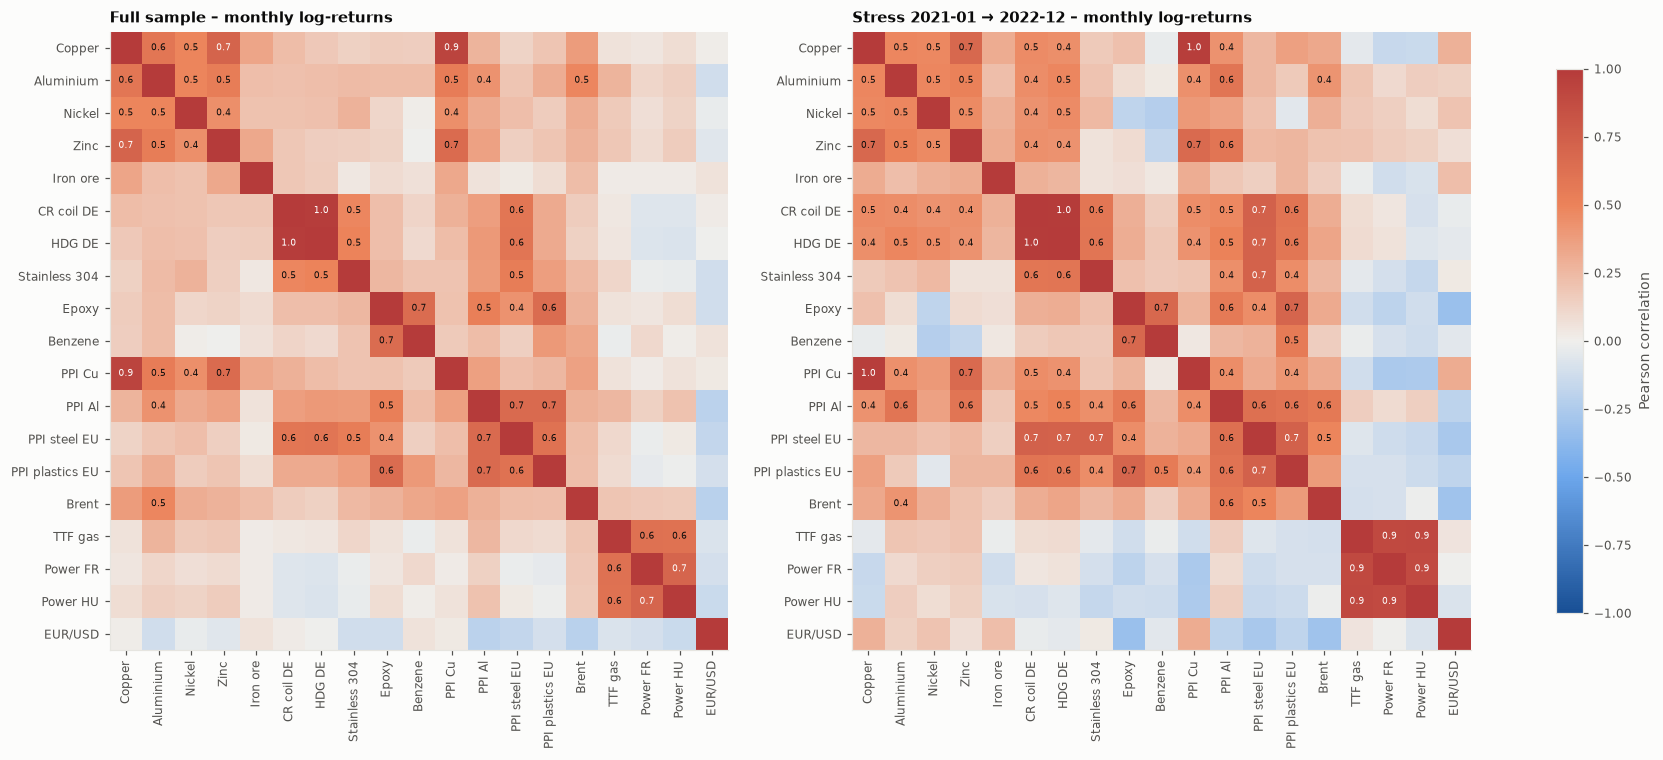

In [15]:
CORR = ["cu_eur", "al_eur", "ni_eur", "zn_eur", "iron_ore_eur", "steel_cr_de", "steel_hdg_de",
        "ss304_de", "epoxy", "benzene", "ppi_cu", "ppi_al", "ppi_steel", "ppi_plastics",
        "brent_eur", "ttf_eur", "power_fr", "power_hu", "eurusd"]
r_win = rets.loc["2016-12":"2026-09", CORR]
full = save(eda.correlation(r_win), "corr_full")
s0, s1 = cfg["stress_window"]
stress = save(eda.correlation(r_win, s0, s1), "corr_stress")
pl.corr_heatmaps(full, stress, PLOTS, f"{s0} → {s1}");

In [16]:
diff = (stress - full).where(np.triu(np.ones(full.shape, bool), 1)).stack().dropna().sort_values()
display(pd.concat([diff.head(6), diff.tail(6)]).to_frame("stress − full"))

,,stress − full
PPI Cu,Power HU,-0.308
Brent,TTF gas,-0.296
Nickel,Epoxy,-0.293
PPI Cu,Power FR,-0.282
Brent,Power FR,-0.270
Epoxy,Power FR,-0.233
TTF gas,Power FR,0.274
Zinc,HDG DE,0.276
PPI Cu,EUR/USD,0.278
CR coil DE,PPI plastics EU,0.279


### Lead–lag
corr(Δx at t−k, Δy at t). Measured on reference months, before publication lags (handled in Step 4).

,corr_lag0,best_lead_m(k>=1),corr_at_best,approx_95%_band
Brent → PPI plastics EU,0.221,1,0.600,0.192
Brent → Epoxy,0.279,1,0.570,0.192
Benzene → Epoxy,0.652,6,0.117,0.192
TTF gas → PPI Al,0.255,1,0.369,0.192
TTF gas → PPI steel EU,0.102,6,0.285,0.192
Power DE → PPI steel EU,0.045,6,0.226,0.192
Nickel → Stainless 304,0.277,1,0.517,0.192
Iron ore → CR coil DE,0.183,1,0.373,0.192
Copper → PPI Cu,0.933,1,0.236,0.192
Aluminium → PPI Al,0.424,1,0.634,0.192


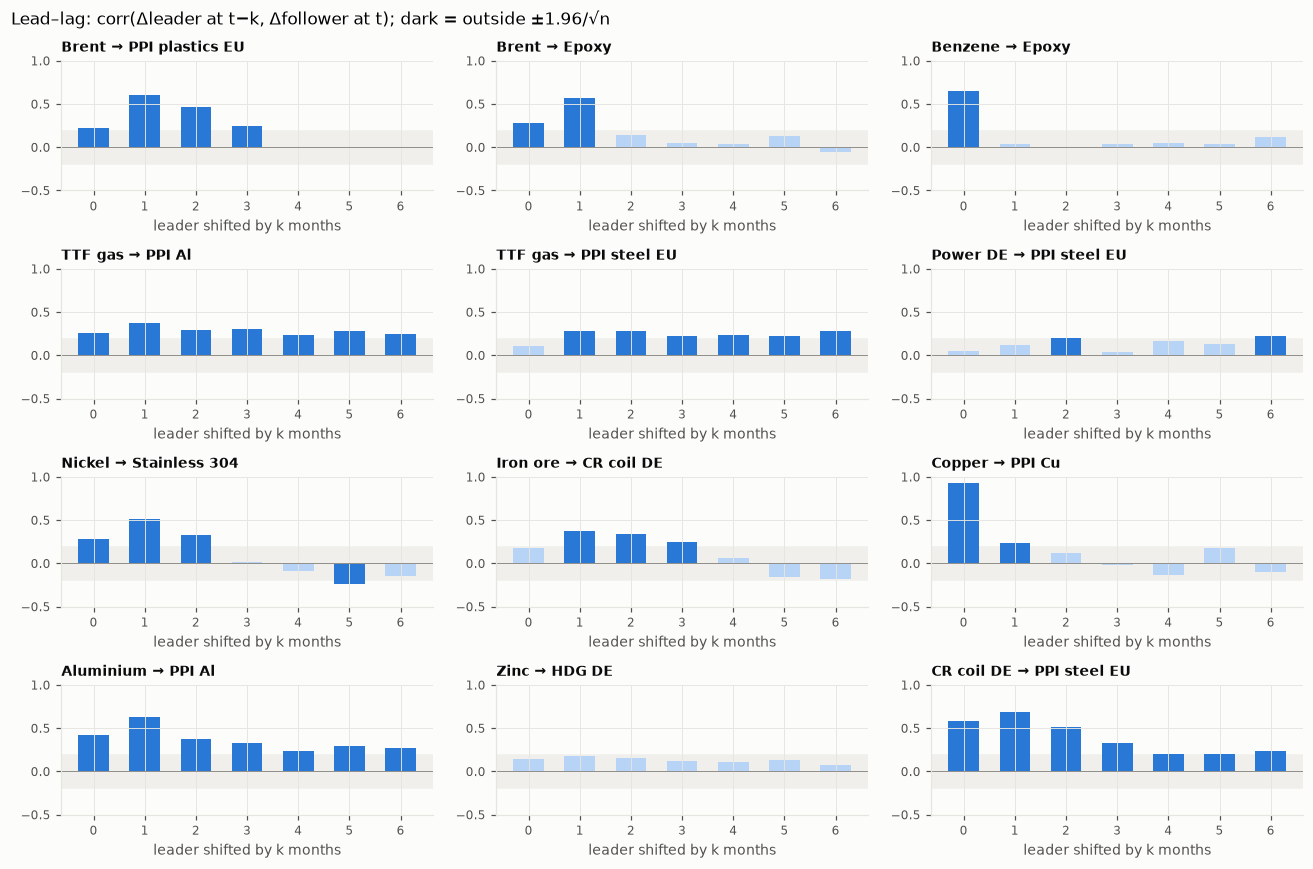

In [17]:
LL = [("brent_eur", "ppi_plastics"), ("brent_eur", "epoxy"), ("benzene", "epoxy"),
      ("ttf_eur", "ppi_al"), ("ttf_eur", "ppi_steel"), ("power_de", "ppi_steel"),
      ("ni_eur", "ss304_de"), ("iron_ore_eur", "steel_cr_de"), ("cu_eur", "ppi_cu"),
      ("al_eur", "ppi_al"), ("zn_eur", "steel_hdg_de"), ("steel_cr_de", "ppi_steel")]
ll1 = eda.lead_lag(win, LL, max_lag=6, change_window=1)
n = int(rets.loc["2016-12":"2026-09"].notna().sum().min())
display(save(eda.lead_lag_summary(ll1, n), "lead_lag_monthly"))
pl.lead_lag_plot(ll1, n, PLOTS);

In [18]:
ll3 = eda.lead_lag(win, LL, max_lag=6, change_window=3)
display(save(eda.lead_lag_summary(ll3, n // 3), "lead_lag_3m"))

,corr_lag0,best_lead_m(k>=1),corr_at_best,approx_95%_band
Brent → PPI plastics EU,0.470,1,0.694,0.336
Brent → Epoxy,0.559,1,0.705,0.336
Benzene → Epoxy,0.633,1,0.474,0.336
TTF gas → PPI Al,0.484,2,0.552,0.336
TTF gas → PPI steel EU,0.339,6,0.458,0.336
Power DE → PPI steel EU,0.227,6,0.405,0.336
Nickel → Stainless 304,0.492,1,0.629,0.336
Iron ore → CR coil DE,0.315,2,0.547,0.336
Copper → PPI Cu,0.965,1,0.767,0.336
Aluminium → PPI Al,0.571,1,0.725,0.336


## 3.3 Business-oriented EDA, using the Step 2 cost model

The raw-material cost of a unit comes from `src/cost_model.py` (Karin): masses, €/t levels at the origin and the
driver series that move each material. Two ways to move the prices back in time:

* **Step 2 drivers** (the team's definition): carbon steel and stainless follow the S09 PPI, galvanised S10, copper D01, aluminium D02, epoxy its own price.
* **Market prices** (sensitivity): each material follows its own €/t series (MEPS, CRU, LME, epoxy). This is closer to what Schneider pays.

For the margin simulation only, a constant non-raw-material cost is added so that the unit cost at the origin is
€3,009 (RM6 teardown) or €3,610 (AirSeT, assumption).

In [19]:
step1 = dl.load_step1_panel(P)
bd = pd.concat({c: cm.cost_breakdown(ec.all_cases()[c], step1, B["origin"]).set_index("material")
                for c in B["cases"]})
display(save(bd[["kg", "level_series", "level_month", "eur_per_t", "driver", "cost_eur", "cost_share"]], "step2_breakdown"))

kg        level_series level_month  eur_per_t     driver  cost_eur  cost_share
                  material                                                                                             
RM6               Carbon steel FR   139.680          MEPS_FR_CR     2026-09    830.000        S09   115.934       0.146
                  Stainless steel    55.800  CRU_SS304_DE_TOTAL     2026-08   2728.000        S09   152.222       0.191
                  Copper             38.800                 D01     2026-09  12570.807        D01   487.747       0.613
                  Galvanised steel   21.100         MEPS_DE_HDG     2026-09    815.000        S10    17.197       0.022
                  Plastic             5.600                 NaN                    NaN        S11       NaN         NaN
                  Aluminium           5.000                 D02     2026-09   2851.550        D02    14.258       0.018
                  Epoxy               1.581           EPOXY_EUR     2026-09   4866.205  EPOXY_EUR     7.693       0.010
AirSeT epoxy low  Carbon steel DE   327.200          MEPS_DE_CR     2026-09    825.000        S09   269.940       0.463
                  Stainless steel   102.600  CRU_SS304_DE_TOTAL     2026-08   2728.000        S09   279.893       0.480
                  Plastic            25.100                 NaN                    NaN        S11       NaN         NaN
                  Aluminium           5.000                 D02     2026-09   2851.550        D02    14.258       0.024
                  Epoxy               3.901           EPOXY_EUR     2026-09   4866.205  EPOXY_EUR    18.984       0.033
AirSeT epoxy high Carbon steel DE   327.200          MEPS_DE_CR     2026-09    825.000        S09   269.940       0.275
                  Stainless steel   102.600  CRU_SS304_DE_TOTAL     2026-08   2728.000        S09   279.893       0.285
                  Plastic            25.100                 NaN                    NaN        S11       NaN         NaN
                  Aluminium           5.000                 D02     2026-09   2851.550        D02    14.258       0.015
                  Epoxy              85.600           EPOXY_EUR     2026-09   4866.205  EPOXY_EUR   416.547       0.425

RM6                                 max gap vs Step 2 bom_index_history: 0.0005 pts
AirSeT epoxy low                    max gap vs Step 2 bom_index_history: 0.0005 pts
AirSeT epoxy high                   max gap vs Step 2 bom_index_history: 0.0005 pts
AirSeT epoxy low, nickel check      max gap vs Step 2 bom_index_history: 0.0005 pts
AirSeT epoxy high, nickel check     max gap vs Step 2 bom_index_history: 0.0005 pts


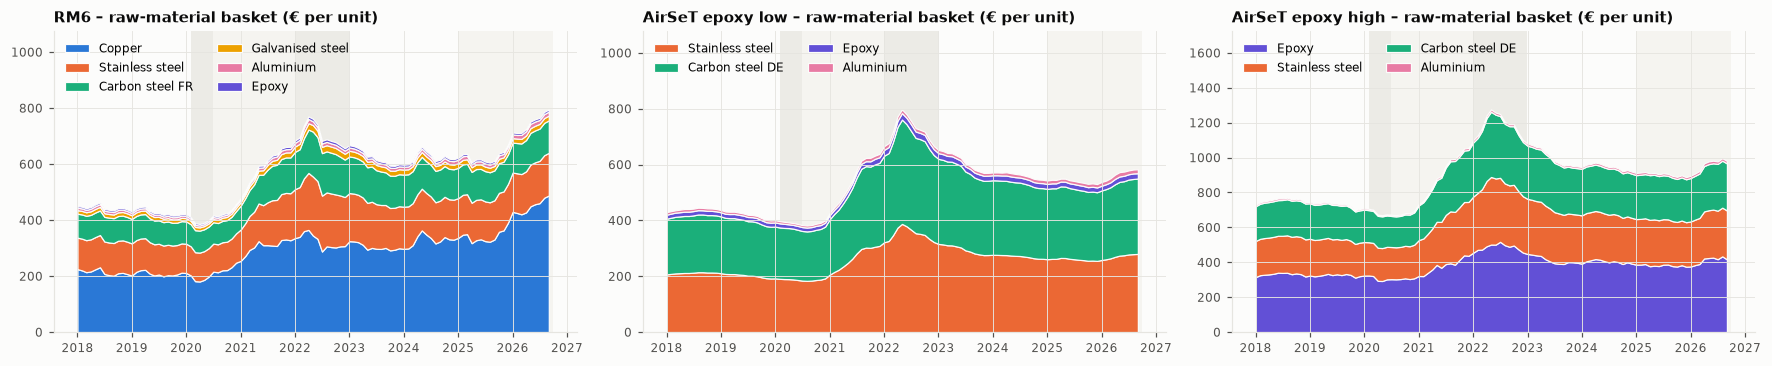

In [20]:
costs = ec.build_costs(step1, B)
hist = pd.read_csv("Data/processed/bom_index_history.csv", index_col=0, parse_dates=True)
for c in B["cases"] + B["nickel_check_cases"]:
    a = costs[(c, "driver")]["bom_index"]
    print(f"{c:35s} max gap vs Step 2 bom_index_history: {(a - hist[c].reindex(a.index)).abs().max():.4f} pts")
driver_costs = {c: costs[(c, "driver")] for c in B["cases"]}
pl.cost_stack(driver_costs, REG, PLOTS);

n   q05_%   q10_%  q50_%   q90_%   q95_%    max_%  P(rise)
case                            drive  H                                                                
RM6                             driver 3  102.0  -7.731  -4.985  0.753  10.495  12.471   17.403    0.569
                                       6   99.0  -8.026  -7.193 -0.424  17.422  24.814   35.860    0.475
                                       9   96.0 -10.662  -8.815  0.139  27.336  37.496   44.836    0.510
                                market 3  101.0  -8.910  -6.532  1.054  13.644  18.964   25.635    0.554
                                       6   98.0 -13.558  -9.613  0.352  23.911  37.463   53.349    0.510
                                       9   95.0 -14.984 -12.155 -1.605  34.606  53.058   70.000    0.463
AirSeT epoxy low                driver 3  102.0  -6.061  -4.492 -0.884  12.246  15.667   19.595    0.412
                                       6   99.0 -10.794  -8.379 -1.713  22.363  28.414   37.376    0.384
                                       9   96.0 -14.221 -11.925 -2.295  32.434  41.501   56.839    0.354
                                market 3  101.0 -17.074  -8.896 -0.441  16.045  24.703   35.667    0.485
                                       6   98.0 -18.444 -14.768 -1.649  26.375  48.396   70.677    0.429
                                       9   95.0 -22.123 -18.390 -5.300  42.914  73.910  100.409    0.358
AirSeT epoxy high               driver 3  102.0  -5.643  -5.117 -0.353  10.272  12.943   16.942    0.412
                                       6   99.0 -10.620  -9.311 -1.274  19.250  23.213   31.456    0.404
                                       9   96.0 -15.171 -11.209 -2.506  30.368  35.374   45.298    0.344
                                market 3  101.0 -12.018  -7.133 -0.156  11.429  18.995   26.111    0.475
                                       6   98.0 -16.400 -10.415 -1.420  22.296  35.609   52.776    0.459
                                       9   95.0 -18.429 -15.129 -3.801  33.128  52.112   70.237    0.379
AirSeT epoxy low, nickel check  driver 3  102.0 -10.517  -8.732 -0.471  11.572  16.037   38.681    0.480
                                       6   99.0 -16.777 -13.280  0.272  20.713  25.194   48.469    0.525
                                       9   96.0 -19.650 -15.042 -2.973  32.021  38.302   63.655    0.427
AirSeT epoxy high, nickel check driver 3  102.0  -8.760  -6.705 -0.718  10.504  11.434   26.960    0.451
                                       6   99.0 -12.909 -10.535 -0.597  19.519  22.398   37.278    0.485
                                       9   96.0 -17.018 -13.349 -1.628  31.568  33.346   50.094    0.417

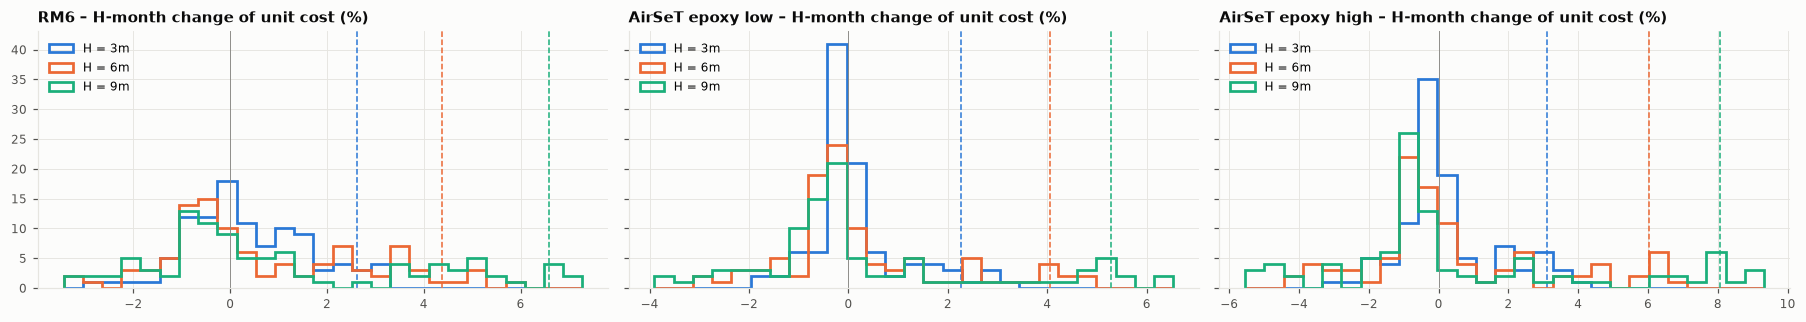

In [21]:
rows = []
for (c, d), df in costs.items():
    for col in ["bom_index", "unit_cost"]:
        t = eda.cost_h_changes(df, H, col)
        t.insert(0, "series", col); t.insert(0, "drive", d); t.insert(0, "case", c)
        rows.append(t.reset_index())
ch = save(pd.concat(rows).set_index(["case", "drive", "series", "H"]), "cost_h_changes")
display(ch.xs("bom_index", level="series"))
pl.cost_change_hist(driver_costs, H, PLOTS);

### Risk decomposition: which material drives the cost risk?

Aluminium  Carbon steel DE  Carbon steel FR  Copper  Epoxy  Galvanised steel  Stainless alloy surcharge  Stainless base  Stainless steel
RM6                            3        2.2              0.0             14.3    62.1    0.6               2.0                        0.0             0.0             18.8
                               6        2.2              0.0             17.5    54.0    0.9               2.3                        0.0             0.0             23.0
                               9        2.2              0.0             19.2    49.8    1.0               2.6                        0.0             0.0             25.2
AirSeT epoxy low               3        1.2             47.6              0.0     0.0    1.9               0.0                        0.0             0.0             49.3
                               6        1.4             47.2              0.0     0.0    2.3               0.0                        0.0             0.0             49.0
                               9        1.6             47.1              0.0     0.0    2.5               0.0                        0.0             0.0             48.8
AirSeT epoxy high              3        0.9             31.0              0.0     0.0   35.9               0.0                        0.0             0.0             32.1
                               6        1.0             30.7              0.0     0.0   36.5               0.0                        0.0             0.0             31.8
                               9        1.1             30.5              0.0     0.0   36.7               0.0                        0.0             0.0             31.7
AirSeT epoxy low, nickel check 3        1.3             18.7              0.0     0.0    0.8               0.0                       75.7             3.6              0.0
                               6        1.3             27.2              0.0     0.0    1.5               0.0                       64.9             5.2              0.0
                               9        1.2             32.8              0.0     0.0    1.8               0.0                       57.9             6.2              0.0

Aluminium  Carbon steel DE  Carbon steel FR  Copper  Epoxy  Galvanised steel  Stainless steel
RM6               3        1.3              0.0             26.0    35.4    0.3               3.9             33.0
                  6        1.5              0.0             25.2    35.2    0.4               3.9             33.9
                  9        1.5              0.0             24.9    34.5    0.5               3.8             34.7
AirSeT epoxy low  3        0.8             50.8              0.0     0.0    0.6               0.0             47.9
                  6        1.0             49.3              0.0     0.0    0.9               0.0             48.9
                  9        1.1             47.3              0.0     0.0    1.1               0.0             50.5
AirSeT epoxy high 3        0.7             42.3              0.0     0.0   14.9               0.0             42.1
                  6        0.8             38.4              0.0     0.0   19.4               0.0             41.4
                  9        0.9             35.5              0.0     0.0   21.9               0.0             41.7

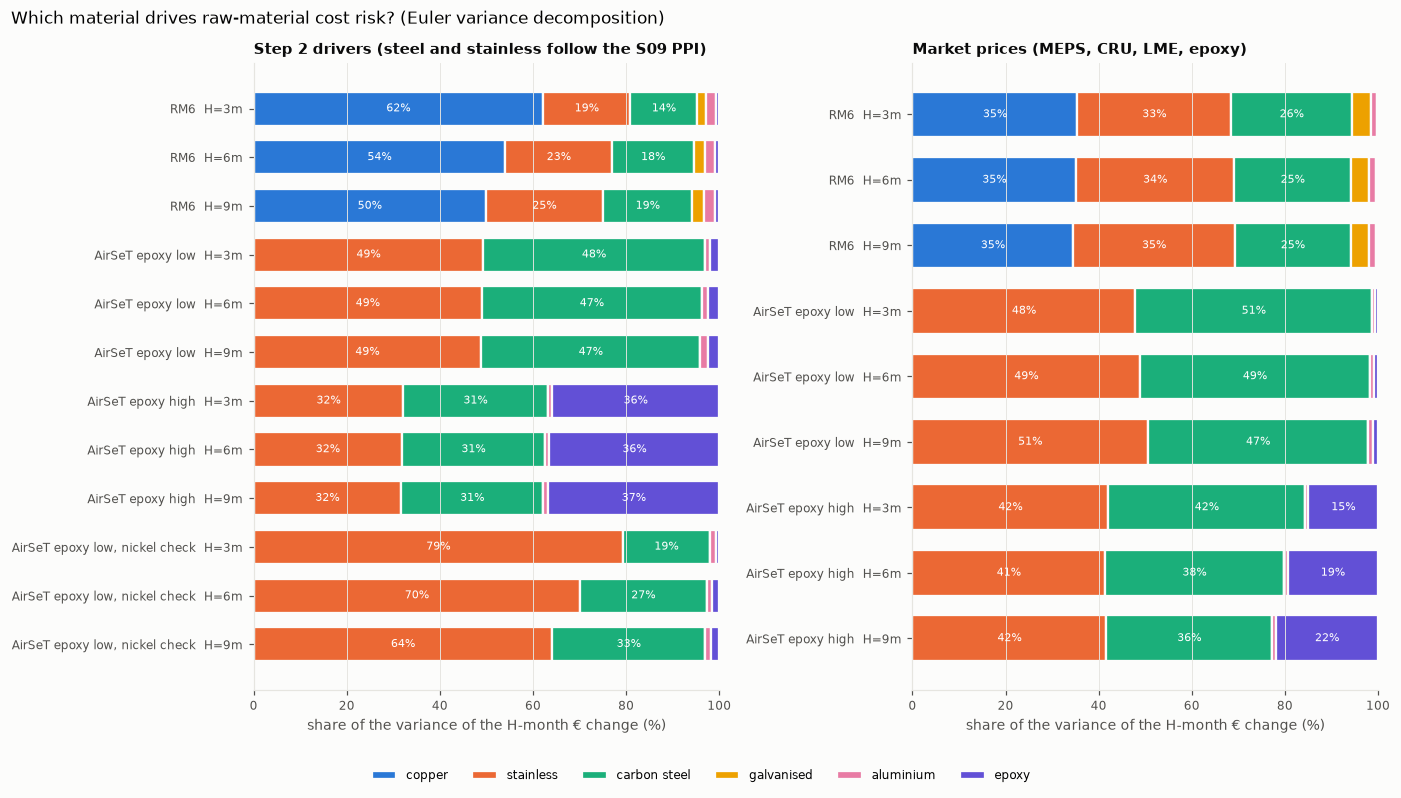

In [22]:
def contributions(keys):
    out = {}
    for c, d in keys:
        mats = ec.materials_of(costs[(c, d)])
        for h in H:
            out[(c, h)] = eda.risk_contribution(costs[(c, d)], mats, h)
    return pd.DataFrame(out).T.fillna(0)

contrib_driver = contributions([(c, "driver") for c in B["cases"] + B["nickel_check_cases"][:1]])
contrib_market = contributions([(c, "market") for c in B["cases"]])
save(contrib_driver, "risk_contribution_step2_drivers"); save(contrib_market, "risk_contribution_market")
display((100 * contrib_driver).round(1)); display((100 * contrib_market).round(1))
pl.risk_contribution_plot({"Step 2 drivers (steel and stainless follow the S09 PPI)": contrib_driver,
                           "Market prices (MEPS, CRU, LME, epoxy)": contrib_market}, PLOTS);

### Historical "margin gamble"
At each past month t, price = unit cost_t / (1 − target margin), fixed for H months; material bought at delivery
(worst case: no early purchase, no indexation, no hedge).

n_origins  mean_erosion_pts  p05_erosion_pts  worst_erosion_pts  P(margin < target)  P(erosion > 2 pts)  buffer_P90_%price  buffer_P95_%price
                         H                                                                                                                                               
RM6               driver 3      102.0            -0.250           -1.837             -2.266               0.569               0.039              1.489              1.837
                         6       99.0            -0.487           -3.059             -4.139               0.475               0.182              2.550              3.059
                         9       96.0            -0.731           -4.606             -5.094               0.510               0.281              3.656              4.606
                  market 3      101.0            -0.231           -2.560             -3.171               0.554               0.109              2.098              2.560
                         6       98.0            -0.453           -4.371             -6.337               0.510               0.204              3.438              4.371
                         9       95.0            -0.676           -6.327             -7.751               0.463               0.274              4.643              6.327
AirSeT epoxy low  driver 3      102.0            -0.090           -1.584             -2.277               0.412               0.020              1.153              1.584
                         6       99.0            -0.178           -2.842             -3.365               0.384               0.111              2.097              2.842
                         9       96.0            -0.255           -3.699             -4.571               0.354               0.167              3.352              3.699
                  market 3      101.0            -0.067           -2.877             -4.027               0.485               0.099              1.510              2.877
                         6       98.0            -0.144           -4.726             -6.441               0.429               0.143              3.246              4.726
                         9       95.0            -0.196           -6.511             -8.383               0.358               0.189              4.071              6.511
AirSeT epoxy high driver 3      102.0            -0.151           -2.178             -2.778               0.412               0.069              1.636              2.178
                         6       99.0            -0.303           -4.224             -4.902               0.404               0.172              3.407              4.224
                         9       96.0            -0.426           -5.647             -6.525               0.344               0.198              5.285              5.647
                  market 3      101.0            -0.131           -3.496             -4.699               0.475               0.119              2.208              3.496
                         6       98.0            -0.268           -5.910             -7.893               0.459               0.184              4.284              5.910
                         9       95.0            -0.365           -8.474            -10.505               0.379               0.232              5.685              8.474

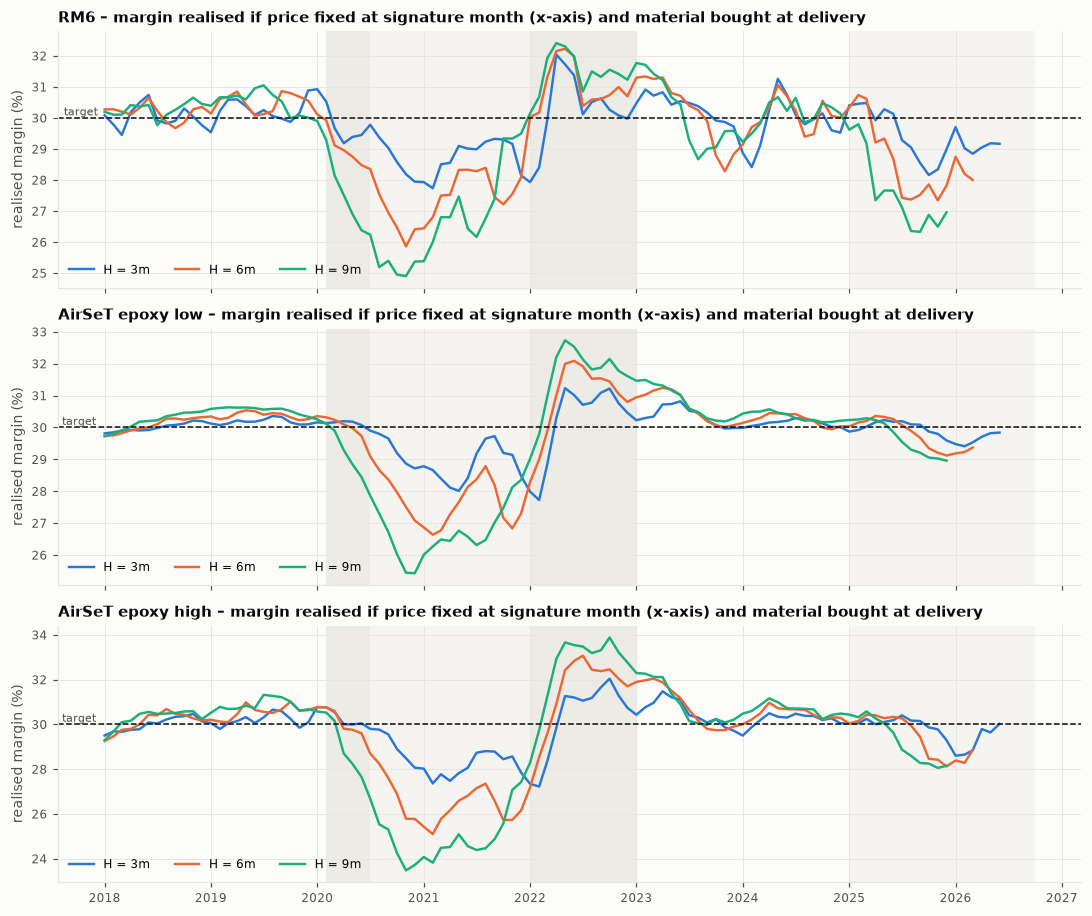

In [23]:
m, tol = B["target_margin"], B["breach_tolerance_pts"]
summ_g = pd.concat({(c, d): eda.margin_gamble_summary(costs[(c, d)], H, m, tol)
                    for (c, d) in costs if "nickel" not in c})
display(save(summ_g, "margin_gamble_summary"))
gambles = {c: {h: eda.margin_gamble(costs[(c, "driver")], h, m) for h in H} for c in B["cases"]}
pl.margin_gamble_plot(gambles, m, REG, PLOTS);

In [24]:
for c in B["cases"]:
    g = gambles[c][9]
    print(c); display((100 * g["erosion_pts"]).nsmallest(3).to_frame("erosion (margin pts), H = 9"))

RM6


,"erosion (margin pts), H = 9"
month,
2020-11-01,-5.094
2020-10-01,-5.050
2020-08-01,-4.806


AirSeT epoxy low


,"erosion (margin pts), H = 9"
month,
2020-12-01,-4.571
2020-11-01,-4.555
2021-01-01,-3.991


AirSeT epoxy high


,"erosion (margin pts), H = 9"
month,
2020-11-01,-6.525
2020-12-01,-6.279
2021-02-01,-6.180


### Does the selling price follow raw-material cost?
Synthetic yearly benchmark P50 (Step 1 output) against the RM6 cost. Step 1 notes that 2026 is distorted by the SF6 ban.

,ABB,Eaton,Ormazabal,Schneider Electric,Siemens,SwitchGear Company,RM6 RM basket,RM6 unit cost
year,,,,,,,,
2018,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2019,101.4,95.8,101.2,100.3,100.4,99.6,96.4,99.4
2020,100.3,97.2,99.9,99.5,100.4,99.3,93.0,98.8
2021,107.4,103.4,111.1,106.2,108.9,106.0,133.4,105.6
2022,113.8,105.4,116.8,113.9,116.6,112.8,158.1,109.7
2023,121.4,106.7,122.1,115.2,121.9,120.6,140.5,106.8
2024,122.0,106.7,124.8,119.6,122.1,123.3,140.1,106.7
2025,121.8,105.6,125.0,119.8,122.1,125.5,140.6,106.8
2026,170.3,114.5,169.7,167.7,162.9,166.0,167.7,111.3


corr(ΔP50 SE, ΔRM6 RM cost)            = 0.42 (n = 8)
corr(ΔP50 SE, ΔRM6 RM cost) excl. 2026 = 0.8


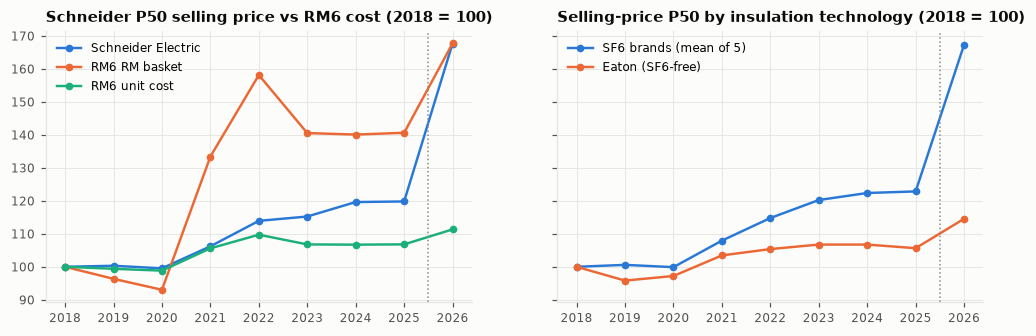

In [25]:
idx = save(eda.price_vs_cost(bench, costs[("RM6", "driver")]), "price_vs_cost_index")
display(idx.round(1))
pl.price_vs_cost_plot(idx, PLOTS);
yoy = idx.pct_change().dropna()
print("corr(ΔP50 SE, ΔRM6 RM cost)            =", round(yoy["Schneider Electric"].corr(yoy["RM6 RM basket"]), 2), f"(n = {len(yoy)})")
print("corr(ΔP50 SE, ΔRM6 RM cost) excl. 2026 =", round(yoy.drop(2026)["Schneider Electric"].corr(yoy.drop(2026)["RM6 RM basket"]), 2))